# 2D Analysis Notebook

This notebook analyzes CSV results from 2D simulations comparing **empathic** vs **non-empathic** agents.

## Configuration (aligned with main_2d.py)
- **Agents**: 6
- **Grid**: 5×5
- **Resources**: 10
- **Empathic Penalty**: -1.0
- **Empathy Alpha**: 0.5 (empathic) vs 0.0 (non-empathic)

## Metrics Analyzed
- **Depletion Step**: Step at which resources first reach 0
- **Avg Resources During Episode**: Mean resource count throughout episode
- **Resources Remaining**: Resources left at episode end
- **Gini Coefficients**: Inequality in consumption and satisfaction
- **Total Consumption**: Resources consumed per episode
- **Empathic Penalty Events**: Number of empathic penalties triggered
- **Inter-Agent Distance**: Average Manhattan distance between agents

## File Format
`results_<sim>_<episodes>_grid<grid>_agents<agents>_resources<resources>_vision<vision>_exploit<exploit>_penalty<penalty>_alpha<alpha>_loop<loop>_<params>_<random>_<suffix>.csv`

# Imports

In [18]:
import numpy as np
import pandas as pd
import os
import re
import matplotlib.pyplot as plt
import seaborn as sns
import ast

# General variables

## Filenames

In [19]:
# Define the pattern for 2D simulation filenames
# Format: results_<sim>_<episodes>_grid<grid>_agents<agents>_resources<resources>_vision<vision>_
#         exploit<exploit>_penalty<penalty>_alpha<alpha>_loop<loop>_<params>_<random>_<suffix>.csv

TwoD_filename_pattern = re.compile(
    r"results_(?P<simulation_index>\d{3})_(?P<episodes>\d+)_"
    r"grid(?P<grid_size>\d+)_"
    r"agents(?P<num_agents>\d+)_"
    r"resources(?P<num_resources>\d+)_"
    r"vision(?P<vision_radius>\d+)_"
    r"exploit(?P<exploit_reward>-?[\d.]+)_"
    r"penalty(?P<empathic_penalty>-?[\d.]+)_"
    r"alpha(?P<alpha>-?[\d.]+)_"
    r"loop(?P<loop_penalty>-?[\d.]+)_"
    r"(?P<learning_rate>[\d.]+)_(?P<gamma>[\d.]+)_(?P<epsilon>[\d.]+)_(?P<epsilon_decay>[\d.]+)_(?P<epsilon_min>[\d.]+)_"
    r"(?P<batch_size>\d+)_(?P<hidden_size>\d+)_(?P<update_target_every>\d+)_"
    r"(?P<random_suffix>\d{6})_(?P<suffix>[a-zA-Z_]+)\.csv"
)

FILENAME_PATTERNS = [TwoD_filename_pattern]

FILENAME_PATTERNS_PAIR = [
    ("2d", TwoD_filename_pattern)
]

# Functions

## CSV processing

### Parameter recovery from filenames

In [20]:
def parse_results_filenames(folder_path: str, filename_patterns=None) -> pd.DataFrame:
    """
    Scans a folder for result filenames and extracts simulation parameters into a DataFrame.

    Args:
        folder_path (str): Path to the folder containing result CSV files.
        filename_patterns (list): List of compiled regex patterns to match filenames.
                                  If None, use global FILENAME_PATTERNS.

    Returns:
        pd.DataFrame: DataFrame containing parsed parameters from filenames.
    """
    if filename_patterns is None:
        filename_patterns = FILENAME_PATTERNS

    data = []

    for filename in os.listdir(folder_path):
        if not filename.endswith(".csv"):
            continue

        matched = False
        for pattern in filename_patterns:
            match = pattern.match(filename)
            if match:
                file_data = match.groupdict()
                file_data["filename"] = filename
                data.append(file_data)
                matched = True
                break  # Stop at the first match
        
        if not matched:
            print(f"Warning: filename did not match any pattern: {filename}")

    if not data:
        print("No matching filenames found.")
        return pd.DataFrame()

    df = pd.DataFrame(data)

    # Optional: convert numeric fields from str to float/int
    for col in df.columns:
        if col not in {"filename", "suffix"}:
            try:
                df[col] = pd.to_numeric(df[col])
            except Exception:
                pass  # leave as string if conversion fails

    return df

In [21]:
def print_unique_parameter_values(df: pd.DataFrame, exclude: list = None):
    """
    Print a table with parameter names and their unique values.

    Args:
        df (pd.DataFrame): The input DataFrame with simulation parameters.
        exclude (list): Optional list of column names to exclude (e.g., ['filename', 'simulation_index']).
    """
    if exclude is None:
        exclude = ['filename', 'simulation_index']

    param_cols = [col for col in df.columns if col not in exclude]

    summary = {
        "parameter": [],
        "unique_values": []
    }

    for col in param_cols:
        summary["parameter"].append(col)
        summary["unique_values"].append(sorted(df[col].dropna().unique().tolist()))

    summary_df = pd.DataFrame(summary)
    print(summary_df)

### Aggregation of csv

In [22]:
def aggregate_results_by_suffix(folder_path: str, target_suffix: str, environment_type: str = None) -> pd.DataFrame:
    '''
    Aggregate CSV files by suffix (e.g., "episode_summary").
    
    Args: 
        folder_path: Path to the folder containing the CSV files
        target_suffix: Ending name of the CSV => "episode_summary" or "step_data"
        environment_type: "2d" (optional filter)

    Returns: 
        Aggregated dataframe
    '''
    all_data = []

    for filename in os.listdir(folder_path):
        if not filename.endswith(".csv"):
            continue

        for source_type, pattern in FILENAME_PATTERNS_PAIR:
            if environment_type and source_type.lower() != environment_type.lower():
                continue

            match = pattern.match(filename)
            if match:
                metadata = match.groupdict()
                if metadata.get("suffix", "").strip() == target_suffix.strip():
                    file_path = os.path.join(folder_path, filename)
                    try:
                        df = pd.read_csv(file_path)
                        for key, value in metadata.items():
                            df[key] = value
                        df["source"] = source_type.lower()  # normalize
                        all_data.append(df)
                    except Exception as e:
                        print(f"Error reading {filename}: {e}")
                break

    if not all_data:
        print(f"No matching files found for suffix '{target_suffix}' and source '{environment_type}'.")
        return pd.DataFrame()

    final_df = pd.concat(all_data, ignore_index=True)

    for col in final_df.columns:
        if col not in {"suffix", "filename", "source"}:
            try:
                final_df[col] = pd.to_numeric(final_df[col])
            except:
                pass

    filtered_tag = f"_{environment_type.lower()}" if environment_type else ""
    output_filename = f"aggregated_{target_suffix}{filtered_tag}.csv"
    output_path = os.path.join(folder_path, output_filename)
    final_df.to_csv(output_path, index=False)
    print(f"Saved aggregated data to: {output_path}")

    return final_df

In [23]:
# --- Compute additional metrics for missing plots ---
# NOTE: These metrics are now computed in main_2d.py and saved to CSV.
# This cell only computes approximations if the metrics are missing from older CSV files.

if 'df_2d_summary' in locals() and len(df_2d_summary) > 0:
    metrics_computed = []
    
    # Check if new metrics already exist in CSV (from updated main_2d.py)
    if 'gini_consumption' not in df_2d_summary.columns:
        # Compute Gini coefficient for consumption (inequality in resource consumption)
        df_2d_summary['gini_consumption'] = compute_gini_for_df(df_2d_summary, "total_exploits_")
        metrics_computed.append('gini_consumption (approximated)')
    else:
        metrics_computed.append('gini_consumption (from CSV)')
    
    if 'depletion_step' not in df_2d_summary.columns:
        # Compute depletion step approximation
        if 'max_steps' in df_2d_summary.columns:
            max_steps_val = df_2d_summary['max_steps'].iloc[0] if len(df_2d_summary) > 0 else 200
        else:
            max_steps_val = df_2d_summary[df_2d_summary['resources_remaining'] > 0]['total_steps'].max() if len(df_2d_summary[df_2d_summary['resources_remaining'] > 0]) > 0 else 200
        
        df_2d_summary['depletion_step'] = df_2d_summary.apply(
            lambda row: row['total_steps'] if row['resources_remaining'] == 0 else max_steps_val,
            axis=1
        )
        metrics_computed.append('depletion_step (approximated)')
    else:
        metrics_computed.append('depletion_step (from CSV)')
    
    if 'avg_resources_during_episode' not in df_2d_summary.columns:
        # Compute average resources during episode (approximation)
        if 'num_resources' in df_2d_summary.columns:
            initial_resources = df_2d_summary['num_resources']
        else:
            initial_resources = df_2d_summary.groupby(['simulation_number', 'episode'])['resources_remaining'].transform('max')
        
        df_2d_summary['avg_resources_during_episode'] = (
            (initial_resources + df_2d_summary['resources_remaining']) / 2
        )
        consumption_ratio = df_2d_summary['total_consumption'] / initial_resources.clip(lower=1)
        adjustment = 1 - (consumption_ratio.clip(upper=1) * 0.3)
        df_2d_summary['avg_resources_during_episode'] = df_2d_summary['avg_resources_during_episode'] * adjustment
        metrics_computed.append('avg_resources_during_episode (approximated)')
    else:
        metrics_computed.append('avg_resources_during_episode (from CSV)')
    
    if 'avg_inter_agent_distance' not in df_2d_summary.columns:
        # This metric cannot be approximated without step-level data
        df_2d_summary['avg_inter_agent_distance'] = np.nan
        metrics_computed.append('avg_inter_agent_distance (not available - needs new simulation)')
    else:
        metrics_computed.append('avg_inter_agent_distance (from CSV)')
    
    if 'gini_satisfaction' not in df_2d_summary.columns:
        df_2d_summary['gini_satisfaction'] = compute_gini_for_df(df_2d_summary, "final_satisfaction_")
        metrics_computed.append('gini_satisfaction (computed)')
    else:
        metrics_computed.append('gini_satisfaction (from CSV)')
    
    if 'empathic_penalties_count' not in df_2d_summary.columns:
        # Sum from per-agent columns
        penalty_cols = [col for col in df_2d_summary.columns if col.startswith('total_empathic_penalties_')]
        if penalty_cols:
            df_2d_summary['empathic_penalties_count'] = df_2d_summary[penalty_cols].sum(axis=1)
            metrics_computed.append('empathic_penalties_count (computed from per-agent)')
    else:
        metrics_computed.append('empathic_penalties_count (from CSV)')
    
    print("Metrics status:")
    for m in metrics_computed:
        print(f"  - {m}")

Metrics status:
  - gini_consumption (from CSV)
  - depletion_step (from CSV)
  - avg_resources_during_episode (from CSV)
  - avg_inter_agent_distance (from CSV)
  - gini_satisfaction (from CSV)
  - empathic_penalties_count (from CSV)


## Data analysis

### Learning verification

In [24]:
def windowed_avg_reward(
    df: pd.DataFrame,
    reward_prefix: str = "total_reward_",
    episode_column: str = "episode",
    simulation_id_column: str = "simulation_number",
    window_size: int = 5,
    aggregation_mode: str = "mean",  # or "best"
    plot: bool = False
) -> pd.DataFrame:
    """
    Computes a windowed moving average of rewards per episode across simulations.

    Args:
        df (pd.DataFrame): Input dataframe.
        reward_prefix (str): Prefix of reward columns per agent.
        episode_column (str): Column name for episodes.
        simulation_id_column (str): Column indicating different simulations.
        window_size (int): Window size for moving average.
        aggregation_mode (str): 'mean' for average across agents, 'best' for max reward among agents.
        plot (bool): Whether to plot the result.

    Returns:
        pd.DataFrame: DataFrame with ['episode', 'mean_reward', 'moving_avg'].
    """
    # Find all columns with the reward prefix
    reward_cols = [col for col in df.columns if col.startswith(reward_prefix)]
    if not reward_cols:
        raise ValueError(f"No columns found with prefix '{reward_prefix}'")

    # Aggregate rewards per row (across agents)
    if aggregation_mode == "mean":
        df["aggregated_reward"] = df[reward_cols].mean(axis=1)
    elif aggregation_mode == "best":
        df["aggregated_reward"] = df[reward_cols].max(axis=1)
    else:
        raise ValueError("aggregation_mode must be 'mean' or 'best'")

    # Group by episode and average across rows(simulations) 
    episode_avg = (
        df.groupby(episode_column)["aggregated_reward"]
        .mean()
        .reset_index()
        .rename(columns={"aggregated_reward": "mean_reward"})
    )

    # Apply centered moving average smoothing
    episode_avg["moving_avg"] = (
        episode_avg["mean_reward"].rolling(window=window_size, min_periods=1, center=True).mean()
    )

    # Optional plotting
    if plot:
        plt.figure(figsize=(10, 5))
        plt.plot(episode_avg[episode_column], episode_avg["moving_avg"], label=f"Moving Avg ({aggregation_mode})")
        plt.xlabel("Episode")
        plt.ylabel("Reward")
        plt.title(f"{aggregation_mode.capitalize()} Agent Reward (Window={window_size})")
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()

    return episode_avg

### Variable calculation

#### Gini coefficient

In [25]:
# --- Plot average time between resource consumptions ---
if 'df_2d_summary' in locals() and len(df_2d_summary) > 0:
    plot_mean_and_range_across_simulations(
        df=df_2d_summary,
        value_col='avg_time_between_consumptions',
        simulation_col='simulation_number',
        episode_col='episode',
        title='Average Time Between Resource Consumptions',
        ylabel='Average Steps Between Consumptions',
        rolling_window=10,
        plot_individual=False
    )

KeyError: 'Column not found: avg_time_between_consumptions'

In [ ]:
# --- Plot resources remaining at end of episode ---
if 'df_2d_summary' in locals() and len(df_2d_summary) > 0:
    plot_mean_and_range_across_simulations(
        df=df_2d_summary,
        value_col='resources_remaining',
        simulation_col='simulation_number',
        episode_col='episode',
        title='Resources Remaining at End of Episode',
        ylabel='Resources Remaining',
        rolling_window=10,
        plot_individual=False
    )

In [ ]:
def gini_coefficient(arr: np.ndarray) -> float:
    """Compute Gini coefficient of a 1D numpy array."""
    arr = arr.flatten()
    if np.amin(arr) < 0:
        arr = arr - np.amin(arr)  # Shift if negative values present
    mean = np.mean(arr)
    if mean == 0:
        return 0.0
    n = len(arr)
    diff_sum = np.sum(np.abs(np.subtract.outer(arr, arr)))
    gini = diff_sum / (2 * n**2 * mean)
    return gini

def parse_value(val):
    # If value is a string that looks like a list, parse it
    if isinstance(val, str):
        try:
            parsed = ast.literal_eval(val)
            if isinstance(parsed, (list, tuple, np.ndarray)):
                return np.array(parsed, dtype=float)
            else:
                return float(parsed)
        except (ValueError, SyntaxError):
            # Not a list or can't parse, try converting directly
            return float(val)
    # If already numeric or array, convert accordingly
    elif isinstance(val, (list, tuple, np.ndarray)):
        return np.array(val, dtype=float)
    else:
        return float(val)

def compute_gini_for_df(df: pd.DataFrame, prefix: str) -> pd.Series:
    """
    Compute Gini coefficient across columns starting with prefix for each row in df.
    
    Args:
        df: pandas DataFrame.
        prefix: string prefix for target columns.
        
    Returns:
        pandas Series with Gini coefficients per row.
    """
    cols = [col for col in df.columns if col.startswith(prefix)]
    if not cols:
        raise ValueError(f"No columns found starting with prefix '{prefix}'")

    def row_gini(row):
        values = []
        for val in row.values:
            parsed_val = parse_value(val)
            # If parsed_val is an array, flatten it, else just append
            if isinstance(parsed_val, np.ndarray):
                values.extend(parsed_val.flatten())
            else:
                values.append(parsed_val)
        values = np.array(values, dtype=float)
        return gini_coefficient(values)

    gini_series = df[cols].apply(row_gini, axis=1)
    return gini_series

In [ ]:
# --- Additional plots matching the empathy comparison figure ---
# Updated to use new metrics from main_2d.py (6 agents, empathic_penalty=-1.0)

if 'df_2d_summary' in locals() and len(df_2d_summary) > 0 and 'alpha' in df_2d_summary.columns:
    # Group by episode and alpha, compute means
    agg_dict = {
        'depletion_step': 'mean',
        'resources_remaining': 'mean',
        'avg_resources_during_episode': 'mean',
        'gini_consumption': 'mean',
        'gini_satisfaction': 'mean',
        'total_consumption': 'mean',
        'total_empathic_penalties': 'mean'
    }
    
    # Add avg_inter_agent_distance if available
    if 'avg_inter_agent_distance' in df_2d_summary.columns and not df_2d_summary['avg_inter_agent_distance'].isna().all():
        agg_dict['avg_inter_agent_distance'] = 'mean'
        has_distance = True
    else:
        has_distance = False
    
    comparison = df_2d_summary.groupby(['episode', 'alpha']).agg(agg_dict).reset_index()
    
    # Calculate moving window size (1/10 of number of episodes)
    max_episode = comparison['episode'].max()
    window_size = max(1, int(max_episode / 10))
    
    # Get max_steps for reference line
    if 'max_steps' in df_2d_summary.columns:
        max_steps_val = df_2d_summary['max_steps'].iloc[0] if len(df_2d_summary) > 0 else 200
    else:
        max_steps_val = df_2d_summary[df_2d_summary['resources_remaining'] > 0]['total_steps'].max() if len(df_2d_summary[df_2d_summary['resources_remaining'] > 0]) > 0 else 200
    
    # Get initial resources for reference line
    if 'num_resources' in df_2d_summary.columns:
        initial_resources = df_2d_summary['num_resources'].iloc[0] if len(df_2d_summary) > 0 else 10
    else:
        initial_resources = 10
    
    # Create figure with 3x3 grid (use all 9 plots if distance available)
    fig, axes = plt.subplots(3, 3, figsize=(18, 15))
    
    for alpha_val in sorted(comparison['alpha'].unique()):
        data = comparison[comparison['alpha'] == alpha_val].copy()
        data = data.sort_values('episode')
        
        # Apply moving average
        for col in agg_dict.keys():
            if col in data.columns:
                data[f'{col}_smooth'] = data[col].rolling(window=window_size, min_periods=1, center=True).mean()
        
        # Determine label and color
        if alpha_val > 0:
            label = 'Empathic'
            color = 'blue'
        else:
            label = 'Non-Empathic'
            color = 'red'
        
        # Row 1: Resource-related metrics
        # Plot 1: Depletion Step
        axes[0, 0].plot(data['episode'], data['depletion_step_smooth'], label=label, color=color, linewidth=2)
        
        # Plot 2: Average Resources During Episode
        axes[0, 1].plot(data['episode'], data['avg_resources_during_episode_smooth'], label=label, color=color, linewidth=2)
        
        # Plot 3: Resources Remaining
        axes[0, 2].plot(data['episode'], data['resources_remaining_smooth'], label=label, color=color, linewidth=2)
        
        # Row 2: Inequality and consumption metrics
        # Plot 4: Gini Consumption
        axes[1, 0].plot(data['episode'], data['gini_consumption_smooth'], label=label, color=color, linewidth=2)
        
        # Plot 5: Gini Satisfaction
        axes[1, 1].plot(data['episode'], data['gini_satisfaction_smooth'], label=label, color=color, linewidth=2)
        
        # Plot 6: Total Consumption
        axes[1, 2].plot(data['episode'], data['total_consumption_smooth'], label=label, color=color, linewidth=2)
        
        # Row 3: Empathic penalties and distance
        # Plot 7: Empathic Penalty Events
        axes[2, 0].plot(data['episode'], data['total_empathic_penalties_smooth'], label=label, color=color, linewidth=2)
        
        # Plot 8: Inter-Agent Distance (if available)
        if has_distance:
            axes[2, 1].plot(data['episode'], data['avg_inter_agent_distance_smooth'], label=label, color=color, linewidth=2)
    
    # Configure axes
    # Row 1
    axes[0, 0].axhline(y=max_steps_val, color='gray', linestyle='--', alpha=0.5, label='Max Steps')
    axes[0, 0].set_xlabel('Episode')
    axes[0, 0].set_ylabel('Depletion Step')
    axes[0, 0].set_title('Step at Which Resources First Depleted', fontweight='bold')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    axes[0, 1].axhline(y=initial_resources, color='green', linestyle='--', alpha=0.5, label=f'Initial ({int(initial_resources)})')
    axes[0, 1].set_xlabel('Episode')
    axes[0, 1].set_ylabel('Average Resources')
    axes[0, 1].set_title('Average Resource Count During Episode', fontweight='bold')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    axes[0, 2].set_xlabel('Episode')
    axes[0, 2].set_ylabel('Resources Remaining')
    axes[0, 2].set_title('Resources Left at Episode End', fontweight='bold')
    axes[0, 2].legend()
    axes[0, 2].grid(True, alpha=0.3)
    
    # Row 2
    axes[1, 0].axhline(y=0, color='green', linestyle='--', alpha=0.5, label='Perfect Equality')
    axes[1, 0].set_xlabel('Episode')
    axes[1, 0].set_ylabel('Gini Coefficient')
    axes[1, 0].set_title('Gini Coefficient (Consumption Inequality)', fontweight='bold')
    axes[1, 0].set_ylim(-0.05, 1.0)
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    axes[1, 1].axhline(y=0, color='green', linestyle='--', alpha=0.5, label='Perfect Equality')
    axes[1, 1].set_xlabel('Episode')
    axes[1, 1].set_ylabel('Gini Coefficient')
    axes[1, 1].set_title('Gini Coefficient (Satisfaction Inequality)', fontweight='bold')
    axes[1, 1].set_ylim(-0.05, 1.0)
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    axes[1, 2].set_xlabel('Episode')
    axes[1, 2].set_ylabel('Total Resources Consumed')
    axes[1, 2].set_title('Total Consumption per Episode', fontweight='bold')
    axes[1, 2].legend()
    axes[1, 2].grid(True, alpha=0.3)
    
    # Row 3
    axes[2, 0].set_xlabel('Episode')
    axes[2, 0].set_ylabel('Penalty Events')
    axes[2, 0].set_title('Empathic Penalty Events per Episode', fontweight='bold')
    axes[2, 0].legend()
    axes[2, 0].grid(True, alpha=0.3)
    
    if has_distance:
        axes[2, 1].set_xlabel('Episode')
        axes[2, 1].set_ylabel('Average Distance')
        axes[2, 1].set_title('Average Inter-Agent Distance', fontweight='bold')
        axes[2, 1].legend()
        axes[2, 1].grid(True, alpha=0.3)
    else:
        axes[2, 1].text(0.5, 0.5, 'Inter-Agent Distance\n(requires new simulation)', 
                        ha='center', va='center', transform=axes[2, 1].transAxes, fontsize=12)
        axes[2, 1].set_title('Average Inter-Agent Distance', fontweight='bold')
        axes[2, 1].axis('off')
    
    # Hide last subplot (or use for summary stats)
    axes[2, 2].axis('off')
    
    # Add summary statistics text
    summary_text = "Configuration:\n"
    summary_text += f"  Agents: {int(df_2d_summary['num_agents'].iloc[0]) if 'num_agents' in df_2d_summary.columns else 6}\n"
    summary_text += f"  Grid: {int(df_2d_summary['grid_size'].iloc[0])}x{int(df_2d_summary['grid_size'].iloc[0])}\n"
    summary_text += f"  Resources: {int(initial_resources)}\n"
    summary_text += f"  Empathic Penalty: {df_2d_summary['empathic_penalty'].iloc[0] if 'empathic_penalty' in df_2d_summary.columns else -1.0}\n"
    summary_text += f"  Episodes: {int(max_episode) + 1}\n"
    summary_text += f"  Smoothing Window: {window_size}"
    
    axes[2, 2].text(0.1, 0.5, summary_text, ha='left', va='center', 
                    transform=axes[2, 2].transAxes, fontsize=11, family='monospace',
                    bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.5))
    
    plt.tight_layout()
    plt.savefig('empathy_comparison_analysis.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print("\nFigure saved as 'empathy_comparison_analysis.png'")

#### Efficiency

In [ ]:
def compute_efficiency_for_df(df: pd.DataFrame, prefix: str, new_column_name: str) -> pd.DataFrame:
    """
    Compute the average across columns starting with a given prefix for each row in df.
    Handles string representations of single-element lists like '[-1.]'.

    Args:
        df (pd.DataFrame): Input DataFrame.
        prefix (str): Prefix for selecting target columns.
        new_column_name (str): Name of the new column to store the computed average.

    Returns:
        pd.DataFrame: DataFrame with the new column added.
    """
    cols = [col for col in df.columns if col.startswith(prefix)]
    if not cols:
        raise ValueError(f"No columns found starting with prefix '{prefix}'")

    for col in cols:
        # Clean column: parse strings like '[-1.]' into float -1.0
        def parse_cell(val):
            if isinstance(val, (float, int)):
                return float(val)
            if isinstance(val, str):
                try:
                    parsed = ast.literal_eval(val)
                    if isinstance(parsed, list) and len(parsed) == 1:
                        return float(parsed[0])
                    return float(parsed)  # just in case it's not a list
                except Exception:
                    raise ValueError(f"Value '{val}' in column '{col}' could not be parsed to float.")
            raise ValueError(f"Unsupported value type {type(val)} in column '{col}'.")

        df[col] = df[col].apply(parse_cell)

    df[new_column_name] = df[cols].mean(axis=1)
    return df

#### Resource depletion

In [ ]:
def compute_depletion_from_summary(df: pd.DataFrame, num_resources_col: str = None) -> pd.DataFrame:
    """
    Compute resource depletion metrics from episode summary data.
    
    Args:
        df: DataFrame with episode summary data
        num_resources_col: Column name for initial number of resources (if None, infer from metadata)
    
    Returns:
        DataFrame with depletion metrics added
    """
    df = df.copy()
    
    # Try to get initial resources from metadata or use a default
    if num_resources_col and num_resources_col in df.columns:
        initial_resources = df[num_resources_col]
    elif 'num_resources' in df.columns:
        initial_resources = df['num_resources']
    else:
        # Use the maximum resources_remaining as initial (approximation)
        initial_resources = df.groupby(['simulation_number', 'episode'])['resources_remaining'].transform('max')
        print("Warning: Using max resources_remaining as initial resources approximation")
    
    # Compute depletion: 1 - (remaining / initial)
    df['depletion_final'] = 1 - df['resources_remaining'] / initial_resources
    
    # Clip to [0, 1] range
    df['depletion_final'] = df['depletion_final'].clip(0, 1)
    
    return df

### Data visualization

In [ ]:
def plot_mean_and_range_across_simulations(
    df: pd.DataFrame,
    value_col: str,               
    simulation_col: str = 'seed',
    episode_col: str = 'episode',
    step_col: str = 'step',
    is_step_csv: bool = False,
    title: str = None,
    ylabel: str = None,
    rolling_window: int = None,
    plot_individual: bool = False  
):
    if is_step_csv:
        group_cols = [simulation_col, episode_col, step_col]
        avg_group_cols = [episode_col, step_col]
    else:
        group_cols = [simulation_col, episode_col]
        avg_group_cols = [episode_col]

    sim_stats = df.groupby(group_cols)[value_col].mean().reset_index()

    agg_funcs = {value_col: ['mean', 'min', 'max']}
    summary = sim_stats.groupby(avg_group_cols).agg(agg_funcs)
    summary.columns = ['mean', 'min', 'max']
    summary = summary.reset_index()

    if rolling_window and rolling_window > 1:
        summary['mean'] = summary['mean'].rolling(rolling_window, min_periods=1, center=True).mean()
        summary['min'] = summary['min'].rolling(rolling_window, min_periods=1, center=True).mean()
        summary['max'] = summary['max'].rolling(rolling_window, min_periods=1, center=True).mean()

    plt.figure(figsize=(10, 6))

    if plot_individual:
        for sim_id, sim_df in sim_stats.groupby(simulation_col):
            x = sim_df[episode_col] if not is_step_csv else sim_df[step_col]
            y = sim_df[value_col]
            if rolling_window:
                y = y.rolling(rolling_window, min_periods=1).mean()
            plt.plot(x, y, color='gray', alpha=0.3, label=f"Sim {sim_id}")

    x_vals = summary[episode_col] if not is_step_csv else summary[step_col]

    plt.fill_between(
        x_vals,
        summary['min'],
        summary['max'],
        color='blue',
        alpha=0.2,
        label='Range (min-max)'
    )

    plt.plot(x_vals, summary['mean'], color='blue', linewidth=2, label='Mean')

    plt.xlabel('Episode' if not is_step_csv else 'Step')
    plt.ylabel(ylabel if ylabel else value_col)
    plt.title(title or f"Mean and range of {value_col}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Analysis of data

In [ ]:
# --- 1. Gather metadata from filenames ---
folder_path = "2D_simulation_results"  # Folder containing the CSV results
if not os.path.exists(folder_path):
    print(f"The folder does not exist: {folder_path}")
    print("Please update folder_path to point to your results folder.")
else:
    parameter_dataframe = parse_results_filenames(folder_path=folder_path)

    desired_params = [
        "alpha", "grid_size", "num_agents", "num_resources", "vision_radius",
        "learning_rate", "gamma", "epsilon", "epsilon_decay", "epsilon_min",
        "batch_size", "hidden_size", "update_target_every"
    ]

    param_cols = [col for col in parameter_dataframe.columns if col in desired_params]
    unique_values_per_param = {col: sorted(parameter_dataframe[col].unique()) for col in param_cols}

    # Convert to DataFrame with param names as columns and unique set of values as rows
    max_len = max(len(v) for v in unique_values_per_param.values()) if unique_values_per_param else 0
    for k in unique_values_per_param:
        unique_values_per_param[k] += [None] * (max_len - len(unique_values_per_param[k]))

    # Display of the unique sets of parameter values
    if unique_values_per_param:
        summary_df = pd.DataFrame(unique_values_per_param)
        print(summary_df.to_string(index=False))
    else:
        print("No parameters found.")

 grid_size  num_agents  num_resources  vision_radius  alpha  learning_rate  gamma  epsilon  epsilon_decay  epsilon_min  batch_size  hidden_size  update_target_every
       5.0         5.0           10.0            2.0    0.0          0.002   0.99      1.0          0.995         0.05        32.0        128.0                 20.0
       NaN         NaN            NaN            NaN    0.5            NaN    NaN      NaN            NaN          NaN         NaN          NaN                  NaN


In [ ]:
# --- Aggregate data for 2D simulations ---
if os.path.exists(folder_path):
    df_2d_summary = aggregate_results_by_suffix(
        folder_path=folder_path,
        target_suffix="episode_summary",
        environment_type="2d"
    )
    
    print(f"\nLoaded {len(df_2d_summary)} rows from episode_summary files.")
    if len(df_2d_summary) > 0:
        print(f"Columns: {list(df_2d_summary.columns)}")
else:
    print(f"Folder {folder_path} does not exist. Please run simulations first.")

Saved aggregated data to: 2D_simulation_results\aggregated_episode_summary_2d.csv

Loaded 600 rows from episode_summary files.
Columns: ['simulation_number', 'seed', 'episode', 'total_steps', 'resources_remaining', 'depletion_step', 'avg_resources_during_episode', 'gini_consumption', 'gini_satisfaction', 'avg_inter_agent_distance', 'empathic_penalties_count', 'total_consumption', 'total_reward_0', 'total_reward_1', 'total_reward_2', 'total_reward_3', 'total_reward_4', 'total_exploits_0', 'total_exploits_1', 'total_exploits_2', 'total_exploits_3', 'total_exploits_4', 'final_satisfaction_0', 'final_satisfaction_1', 'final_satisfaction_2', 'final_satisfaction_3', 'final_satisfaction_4', 'consumption_per_agent_0', 'consumption_per_agent_1', 'consumption_per_agent_2', 'consumption_per_agent_3', 'consumption_per_agent_4', 'simulation_index', 'episodes', 'grid_size', 'num_agents', 'num_resources', 'vision_radius', 'exploit_reward', 'empathic_penalty', 'alpha', 'loop_penalty', 'learning_rate',

In [ ]:
# --- Compute derived metrics ---
if 'df_2d_summary' in locals() and len(df_2d_summary) > 0:
    # Compute efficiency (mean reward across agents)
    df_2d_summary = compute_efficiency_for_df(df_2d_summary, "total_reward_", "mean_reward")
    
    # Compute Gini coefficient for rewards (inequality measure)
    df_2d_summary['gini_reward'] = compute_gini_for_df(df_2d_summary, "total_reward_")
    
    # Compute Gini coefficient for satisfactions
    df_2d_summary['gini_satisfaction'] = compute_gini_for_df(df_2d_summary, "final_satisfaction_")
    
    # Compute resource depletion
    df_2d_summary = compute_depletion_from_summary(df_2d_summary)
    
    # Compute mean satisfaction
    df_2d_summary = compute_efficiency_for_df(df_2d_summary, "final_satisfaction_", "mean_satisfaction")
    
    # Compute mean emotion
    df_2d_summary = compute_efficiency_for_df(df_2d_summary, "final_emotion_", "mean_emotion")
    
    # Compute average time between resource consumptions per agent
    # For each agent: average_steps_per_exploit = total_steps / total_exploits (if exploits > 0)
    exploit_cols = [col for col in df_2d_summary.columns if col.startswith('total_exploits_')]
    avg_time_between_consumptions = []
    
    for idx, row in df_2d_summary.iterrows():
        total_steps = row['total_steps']
        times = []
        for col in exploit_cols:
            exploits = row[col]
            if exploits > 0:
                # Average steps per exploit = total_steps / number_of_exploits
                avg_steps = total_steps / exploits
                times.append(avg_steps)
        # Average across all agents (only those with exploits > 0)
        if times:
            avg_time_between_consumptions.append(np.mean(times))
        else:
            avg_time_between_consumptions.append(np.nan)  # No exploits in this episode
    
    df_2d_summary['avg_time_between_consumptions'] = avg_time_between_consumptions
    
    # Compute total consumption per episode (sum of all agents' exploits)
    exploit_cols = [col for col in df_2d_summary.columns if col.startswith('total_exploits_')]
    df_2d_summary['total_consumption'] = df_2d_summary[exploit_cols].sum(axis=1)
    
    # Compute total empathic penalty events per episode (sum of all agents' penalties)
    penalty_cols = [col for col in df_2d_summary.columns if col.startswith('total_empathic_penalties_')]
    df_2d_summary['total_empathic_penalties'] = df_2d_summary[penalty_cols].sum(axis=1)
    
    print("Derived metrics computed successfully.")
    print(f"Sample metrics for first episode:")
    print(df_2d_summary[['episode', 'mean_reward', 'gini_reward', 'mean_satisfaction', 'depletion_final', 'avg_time_between_consumptions', 'total_consumption', 'total_empathic_penalties']].head())

ValueError: No columns found starting with prefix 'final_emotion_'

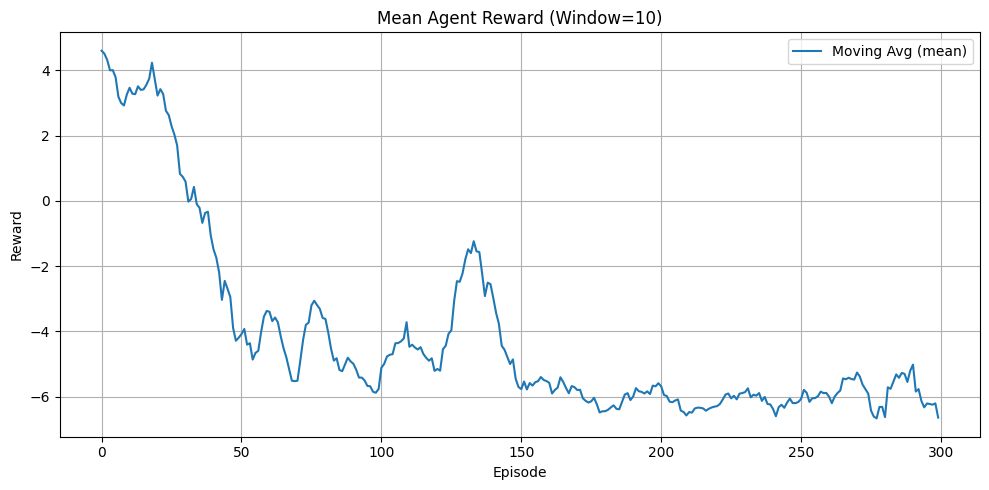

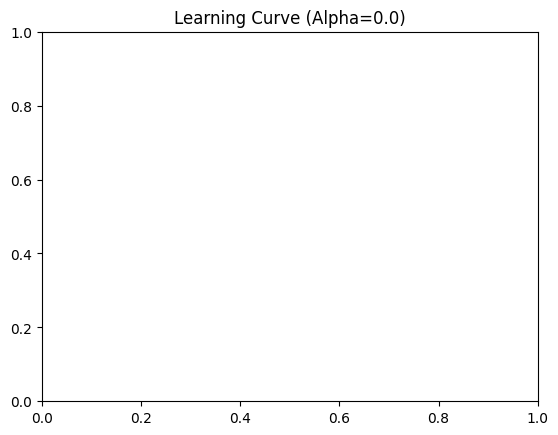

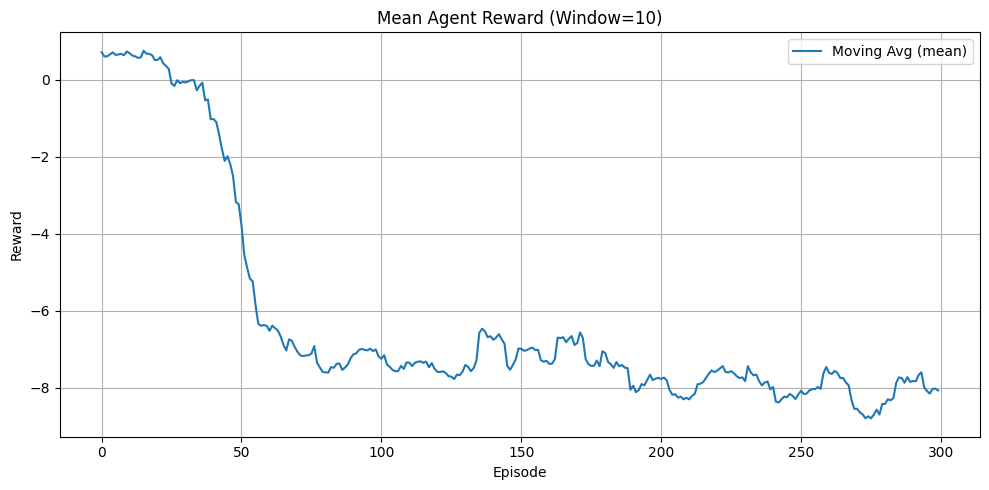

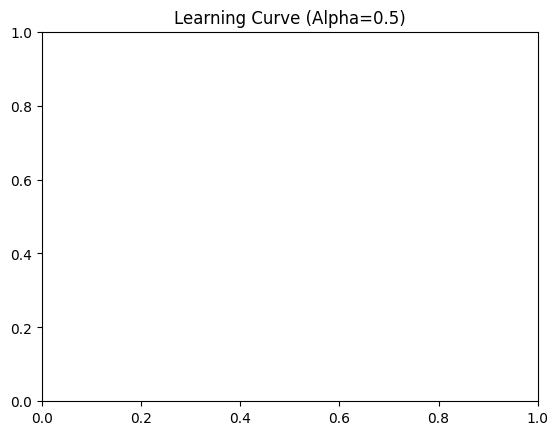

In [ ]:
# --- Learning curve analysis ---
if 'df_2d_summary' in locals() and len(df_2d_summary) > 0:
    # Group by alpha (empathy condition) if available
    if 'alpha' in df_2d_summary.columns:
        for alpha_val in sorted(df_2d_summary['alpha'].unique()):
            df_filtered = df_2d_summary[df_2d_summary['alpha'] == alpha_val].copy()
            
            windowed_df = windowed_avg_reward(
                df=df_filtered,
                reward_prefix="total_reward_",
                episode_column="episode",
                simulation_id_column="simulation_number", 
                window_size=10,
                aggregation_mode="mean",
                plot=True
            )
            plt.title(f"Learning Curve (Alpha={alpha_val})")
            plt.show()
    else:
        windowed_df = windowed_avg_reward(
            df=df_2d_summary,
            reward_prefix="total_reward_",
            episode_column="episode",
            simulation_id_column="simulation_number", 
            window_size=10,
            aggregation_mode="mean",
            plot=True
        )

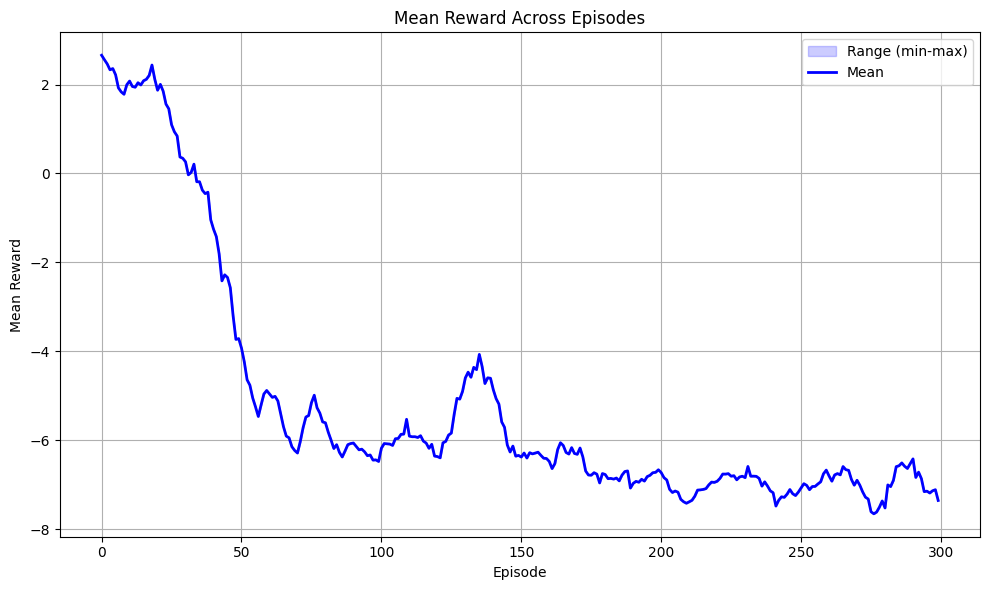

In [ ]:
# --- Plot mean reward over episodes ---
if 'df_2d_summary' in locals() and len(df_2d_summary) > 0:
    plot_mean_and_range_across_simulations(
        df=df_2d_summary,
        value_col='mean_reward',
        simulation_col='simulation_number',
        episode_col='episode',
        title='Mean Reward Across Episodes',
        ylabel='Mean Reward',
        rolling_window=10,
        plot_individual=False
    )

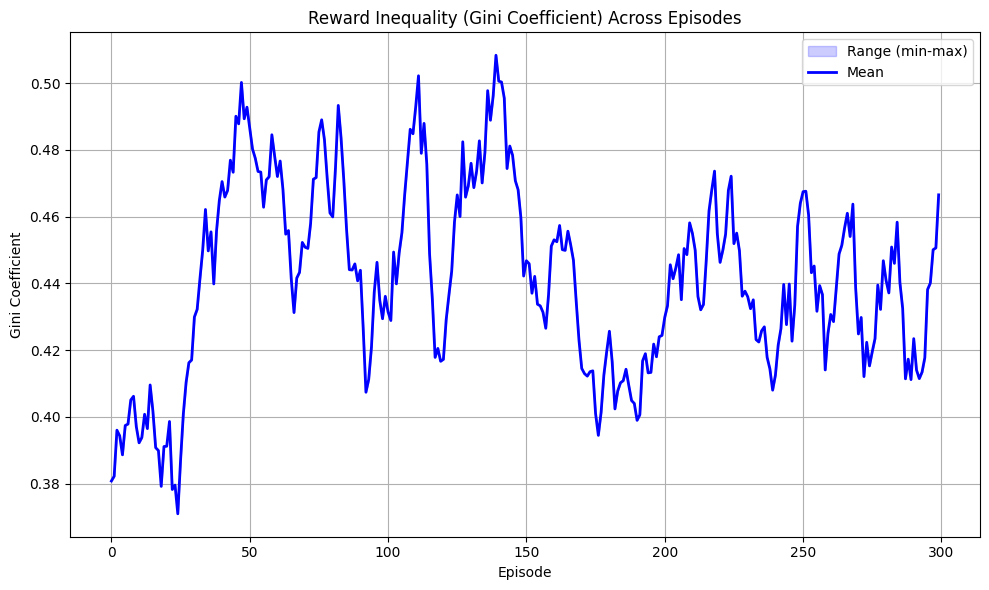

In [ ]:
# --- Plot Gini coefficient (inequality) over episodes ---
if 'df_2d_summary' in locals() and len(df_2d_summary) > 0:
    plot_mean_and_range_across_simulations(
        df=df_2d_summary,
        value_col='gini_reward',
        simulation_col='simulation_number',
        episode_col='episode',
        title='Reward Inequality (Gini Coefficient) Across Episodes',
        ylabel='Gini Coefficient',
        rolling_window=10,
        plot_individual=False
    )

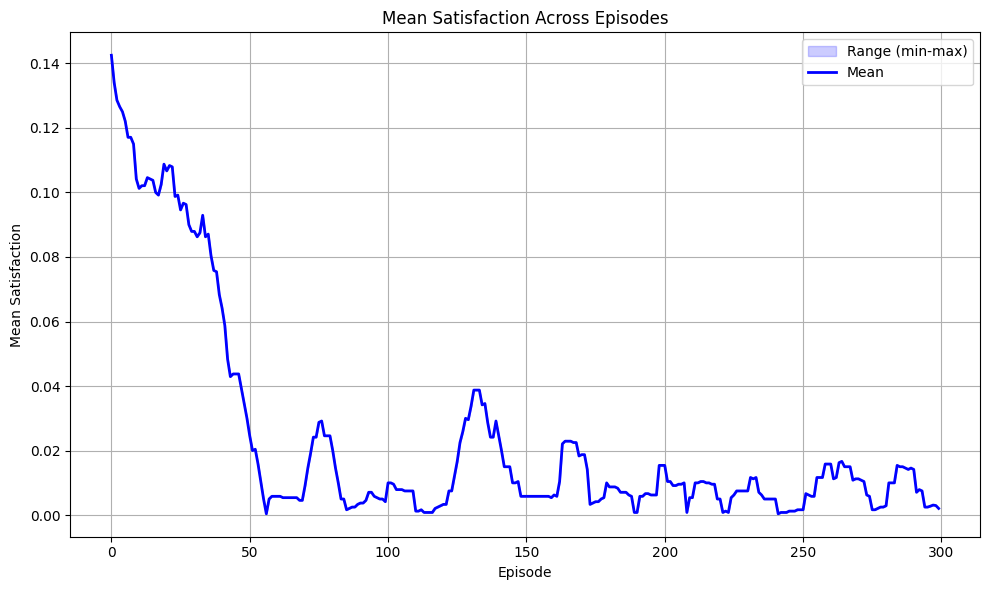

In [ ]:
# --- Plot satisfaction over episodes ---
if 'df_2d_summary' in locals() and len(df_2d_summary) > 0:
    plot_mean_and_range_across_simulations(
        df=df_2d_summary,
        value_col='mean_satisfaction',
        simulation_col='simulation_number',
        episode_col='episode',
        title='Mean Satisfaction Across Episodes',
        ylabel='Mean Satisfaction',
        rolling_window=10,
        plot_individual=False
    )

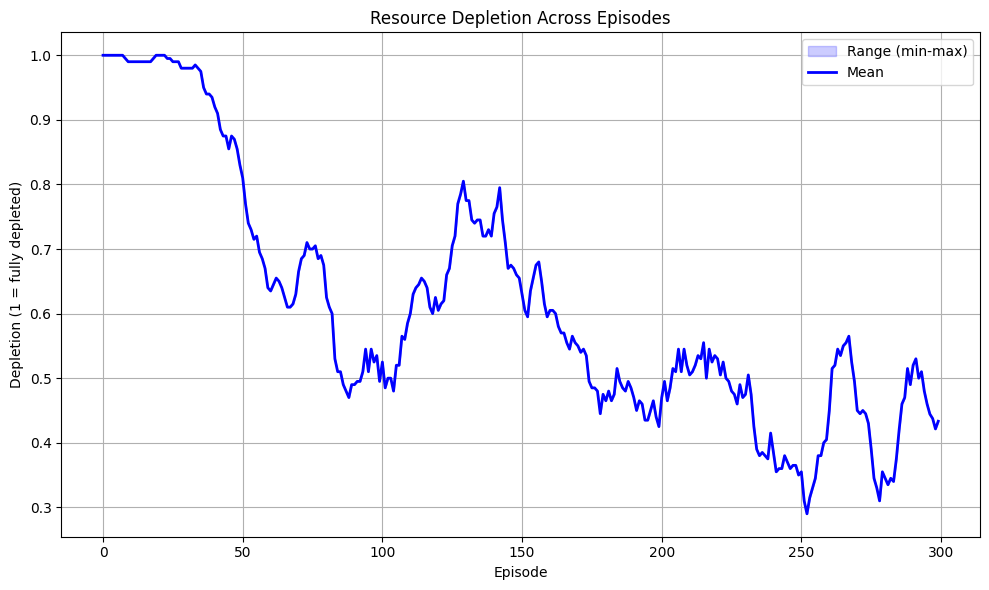

In [ ]:
# --- Plot resource depletion over episodes ---
if 'df_2d_summary' in locals() and len(df_2d_summary) > 0:
    plot_mean_and_range_across_simulations(
        df=df_2d_summary,
        value_col='depletion_final',
        simulation_col='simulation_number',
        episode_col='episode',
        title='Resource Depletion Across Episodes',
        ylabel='Depletion (1 = fully depleted)',
        rolling_window=10,
        plot_individual=False
    )

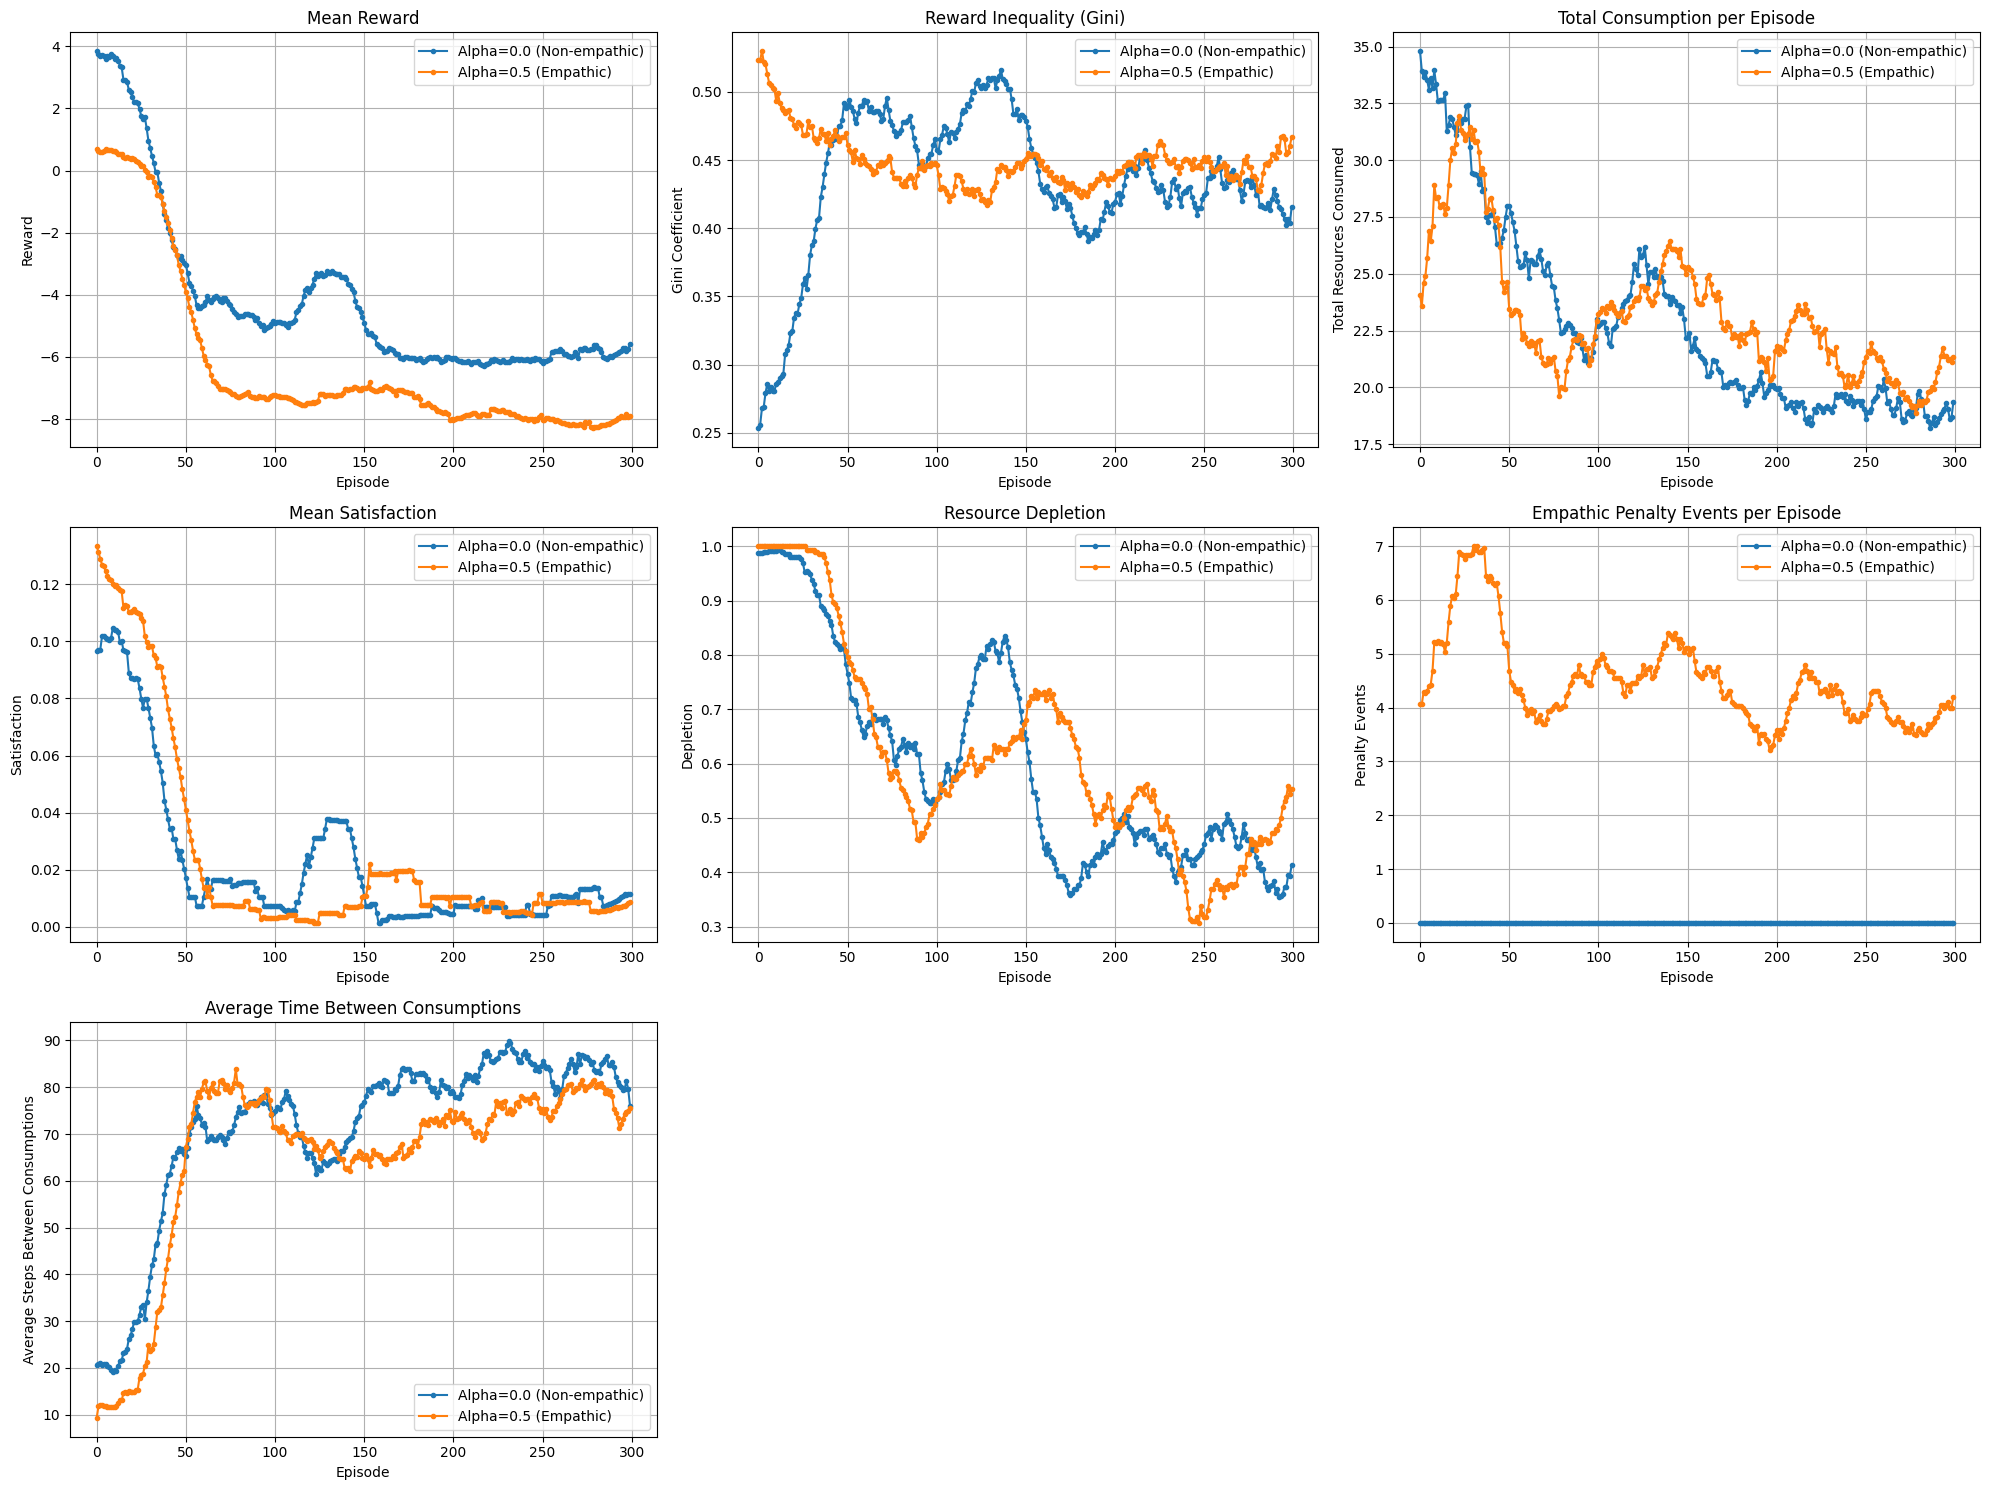

In [ ]:
# --- Compare empathic vs non-empathic conditions ---
if 'df_2d_summary' in locals() and len(df_2d_summary) > 0 and 'alpha' in df_2d_summary.columns:
    # Group by episode and alpha, compute means
    comparison = df_2d_summary.groupby(['episode', 'alpha']).agg({
        'mean_reward': 'mean',
        'gini_reward': 'mean',
        'mean_satisfaction': 'mean',
        'depletion_final': 'mean',
        'avg_time_between_consumptions': 'mean',
        'total_consumption': 'mean',
        'total_empathic_penalties': 'mean'
    }).reset_index()
    
    # Calculate moving window size (1/10 of number of episodes)
    max_episode = comparison['episode'].max()
    window_size = max(1, int(max_episode / 10))
    
    fig, axes = plt.subplots(3, 3, figsize=(20, 15))
    
    for alpha_val in sorted(comparison['alpha'].unique()):
        data = comparison[comparison['alpha'] == alpha_val].copy()
        data = data.sort_values('episode')  # Ensure sorted by episode
        
        # Apply moving average with calculated window size
        data['mean_reward_smooth'] = data['mean_reward'].rolling(window=window_size, min_periods=1, center=True).mean()
        data['gini_reward_smooth'] = data['gini_reward'].rolling(window=window_size, min_periods=1, center=True).mean()
        data['mean_satisfaction_smooth'] = data['mean_satisfaction'].rolling(window=window_size, min_periods=1, center=True).mean()
        data['depletion_final_smooth'] = data['depletion_final'].rolling(window=window_size, min_periods=1, center=True).mean()
        data['avg_time_between_consumptions_smooth'] = data['avg_time_between_consumptions'].rolling(window=window_size, min_periods=1, center=True).mean()
        data['total_consumption_smooth'] = data['total_consumption'].rolling(window=window_size, min_periods=1, center=True).mean()
        data['total_empathic_penalties_smooth'] = data['total_empathic_penalties'].rolling(window=window_size, min_periods=1, center=True).mean()
        
        label = f"Alpha={alpha_val} (Empathic)" if alpha_val > 0 else "Alpha=0.0 (Non-empathic)"
        
        axes[0, 0].plot(data['episode'], data['mean_reward_smooth'], label=label, marker='o', markersize=3)
        axes[0, 1].plot(data['episode'], data['gini_reward_smooth'], label=label, marker='o', markersize=3)
        axes[0, 2].plot(data['episode'], data['total_consumption_smooth'], label=label, marker='o', markersize=3)
        axes[1, 0].plot(data['episode'], data['mean_satisfaction_smooth'], label=label, marker='o', markersize=3)
        axes[1, 1].plot(data['episode'], data['depletion_final_smooth'], label=label, marker='o', markersize=3)
        axes[1, 2].plot(data['episode'], data['total_empathic_penalties_smooth'], label=label, marker='o', markersize=3)
        axes[2, 0].plot(data['episode'], data['avg_time_between_consumptions_smooth'], label=label, marker='o', markersize=3)
    
    axes[0, 0].set_title('Mean Reward')
    axes[0, 0].set_xlabel('Episode')
    axes[0, 0].set_ylabel('Reward')
    axes[0, 0].legend()
    axes[0, 0].grid(True)
    
    axes[0, 1].set_title('Reward Inequality (Gini)')
    axes[0, 1].set_xlabel('Episode')
    axes[0, 1].set_ylabel('Gini Coefficient')
    axes[0, 1].legend()
    axes[0, 1].grid(True)
    
    axes[0, 2].set_title('Total Consumption per Episode')
    axes[0, 2].set_xlabel('Episode')
    axes[0, 2].set_ylabel('Total Resources Consumed')
    axes[0, 2].legend()
    axes[0, 2].grid(True)
    
    axes[1, 0].set_title('Mean Satisfaction')
    axes[1, 0].set_xlabel('Episode')
    axes[1, 0].set_ylabel('Satisfaction')
    axes[1, 0].legend()
    axes[1, 0].grid(True)
    
    axes[1, 1].set_title('Resource Depletion')
    axes[1, 1].set_xlabel('Episode')
    axes[1, 1].set_ylabel('Depletion')
    axes[1, 1].legend()
    axes[1, 1].grid(True)
    
    axes[1, 2].set_title('Empathic Penalty Events per Episode')
    axes[1, 2].set_xlabel('Episode')
    axes[1, 2].set_ylabel('Penalty Events')
    axes[1, 2].legend()
    axes[1, 2].grid(True)
    
    axes[2, 0].set_title('Average Time Between Consumptions')
    axes[2, 0].set_xlabel('Episode')
    axes[2, 0].set_ylabel('Average Steps Between Consumptions')
    axes[2, 0].legend()
    axes[2, 0].grid(True)
    
    # Hide the unused subplots
    axes[2, 1].axis('off')
    axes[2, 2].axis('off')
    
    plt.tight_layout()
    plt.show()

In [ ]:
# --- Statistical Comparison (Last N Episodes) ---
from scipy import stats

if 'df_2d_summary' in locals() and len(df_2d_summary) > 0 and 'alpha' in df_2d_summary.columns:
    last_n = 20  # Compare last 20 episodes
    
    print("="*60)
    print(f"STATISTICAL COMPARISON (Last {last_n} Episodes)")
    print("="*60)
    
    def compare_metric(name, metric_col):
        """Compare a metric between empathic and non-empathic conditions."""
        max_episode = df_2d_summary['episode'].max()
        last_episodes = df_2d_summary[df_2d_summary['episode'] > max_episode - last_n]
        
        ne_data = last_episodes[last_episodes['alpha'] == 0.0][metric_col].dropna()
        e_data = last_episodes[last_episodes['alpha'] > 0][metric_col].dropna()
        
        if len(ne_data) == 0 or len(e_data) == 0:
            print(f"\n{name}: Insufficient data")
            return
        
        ne_mean, ne_std = np.mean(ne_data), np.std(ne_data)
        e_mean, e_std = np.mean(e_data), np.std(e_data)
        
        # Mann-Whitney U test (non-parametric)
        try:
            stat, p_value = stats.mannwhitneyu(ne_data, e_data, alternative='two-sided')
            sig = "*" if p_value < 0.05 else ""
            sig = "**" if p_value < 0.01 else sig
            sig = "***" if p_value < 0.001 else sig
        except:
            p_value = 1.0
            sig = ""
        
        pct_change = (e_mean - ne_mean) / (ne_mean + 1e-6) * 100
        
        print(f"\n{name}:")
        print(f"  Non-Empathic: {ne_mean:.3f} ± {ne_std:.3f}")
        print(f"  Empathic:     {e_mean:.3f} ± {e_std:.3f}")
        print(f"  Difference:   {e_mean - ne_mean:+.3f} ({pct_change:+.1f}%)")
        print(f"  p-value:      {p_value:.4f} {sig}")
    
    # Compare key metrics
    compare_metric("Depletion Step", "depletion_step")
    compare_metric("Resources Remaining", "resources_remaining")
    compare_metric("Avg Resources During Episode", "avg_resources_during_episode")
    compare_metric("Gini (Consumption)", "gini_consumption")
    compare_metric("Gini (Satisfaction)", "gini_satisfaction")
    compare_metric("Total Consumption", "total_consumption")
    
    if 'avg_inter_agent_distance' in df_2d_summary.columns:
        compare_metric("Avg Inter-Agent Distance", "avg_inter_agent_distance")
    
    print("\n" + "="*60)
    print("Significance: * p<0.05, ** p<0.01, *** p<0.001")
    print("="*60)

STATISTICAL COMPARISON (Last 20 Episodes)

Depletion Step:
  Non-Empathic: 190.750 ± 40.320
  Empathic:     195.850 ± 18.089
  Difference:   +5.100 (+2.7%)
  p-value:      1.0000 

Resources Remaining:
  Non-Empathic: 6.400 ± 2.478
  Empathic:     4.800 ± 2.821
  Difference:   -1.600 (-25.0%)
  p-value:      0.0711 

Avg Resources During Episode:
  Non-Empathic: 7.613 ± 2.028
  Empathic:     6.261 ± 2.238
  Difference:   -1.352 (-17.8%)
  p-value:      0.0583 

Gini (Consumption):
  Non-Empathic: 0.318 ± 0.100
  Empathic:     0.284 ± 0.108
  Difference:   -0.034 (-10.6%)
  p-value:      0.2082 

Gini (Satisfaction):
  Non-Empathic: 0.270 ± 0.371
  Empathic:     0.154 ± 0.310
  Difference:   -0.116 (-42.8%)
  p-value:      0.3350 

Total Consumption:
  Non-Empathic: 19.050 ± 6.376
  Empathic:     21.400 ± 4.510
  Difference:   +2.350 (+12.3%)
  p-value:      0.1156 

Avg Inter-Agent Distance:
  Non-Empathic: 3.462 ± 0.276
  Empathic:     3.876 ± 0.361
  Difference:   +0.414 (+11.9%)
  p